In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

from meles.detection import YuNetDetector, align_face
from meles.anonymization.anonymizer import (
    BlackBarAnonymizer,
    GaussianBlurAnonymizer,
    PixelationAnonymizer, NoAnonymizer,
)

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load some image samples from the dataset
DATASET_PATH = Path("../../data")
N_SAMPLES = 5

structure = pd.read_parquet(DATASET_PATH / "ytfaces.parquet")
samples = structure.sample(n=N_SAMPLES)
samples

,identity,video,frame,frame_suffix,path
2095,Ahmed_Ahmed,0,aligned_detect_0.811.jpg,.jpg,ytfaces/Ahmed_Ahmed/0/aligned_detect_0.811.jpg
3976,Alberto_Gonzales,2,aligned_detect_2.148.jpg,.jpg,ytfaces/Alberto_Gonzales/2/aligned_detect_2.14...
28810,Clint_Howard,1,aligned_detect_1.209.jpg,.jpg,ytfaces/Clint_Howard/1/aligned_detect_1.209.jpg
116527,Sanjay_Gupta,1,aligned_detect_1.5402.jpg,.jpg,ytfaces/Sanjay_Gupta/1/aligned_detect_1.5402.jpg
130239,Zhong_Nanshan,5,aligned_detect_5.524.jpg,.jpg,ytfaces/Zhong_Nanshan/5/aligned_detect_5.524.jpg


In [3]:
# Anonymization methods. Each of them takes a frame and a detected facial area and
# returns a copy of the frame in which only that area is anonymized. The parameters are
# relative to the size of the facial area, so that the anonymization strength does not
# depend on the resolution of the frame.
#
# These are the same objects the workflow uses, imported rather than redefined here, so
# that what this notebook shows cannot drift away from what `anonymize_frame` actually
# does to the dataset.

ANONYMIZATION_METHODS = {
    "none": NoAnonymizer(),
    "gaussian_blur": GaussianBlurAnonymizer(),
    "pixelation": PixelationAnonymizer(),
    "black_bar": BlackBarAnonymizer(),
}

# The detector the workflow uses. YuNet also returns five landmarks, which is what lets a
# single alignment routine feed all three embedding models.
detector = YuNetDetector()

In [4]:
# Anonymize the face for every sample with every method. The result of a method is a
# dataframe of the encoded frames ("image") together with the index the frame has in the
# dataset structure ("index"), so that it can be joined back onto `samples` later on.
results: dict[str, pd.DataFrame] = {}
for method, anonymizer in ANONYMIZATION_METHODS.items():
    _anonymized = []
    for index, sample in tqdm(samples.iterrows(), total=len(samples), desc=method):
        image = cv2.imread(str(DATASET_PATH / sample["path"]))
        faces = detector.detect(image)

        # Anonymize every detected region, so that frames with multiple faces are
        # covered completely.
        for face in faces:
            image = anonymizer.apply(image, face)

        # The frame is encoded in its original format to keep the dataframe
        # self-contained.
        success, buffer = cv2.imencode(sample["frame_suffix"], image)
        if not success:
            raise ValueError(f"Failed to encode frame: {sample['path']}")
        _anonymized.append({"image": buffer.tobytes(), "index": index})
    results[method] = pd.DataFrame(_anonymized)

results["gaussian_blur"]

black_bar: 100%|██████████| 5/5 [00:00<00:00, 112.43it/s]


,image,index
0,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,2095
1,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,3976
2,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,28810
3,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,116527
4,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,130239


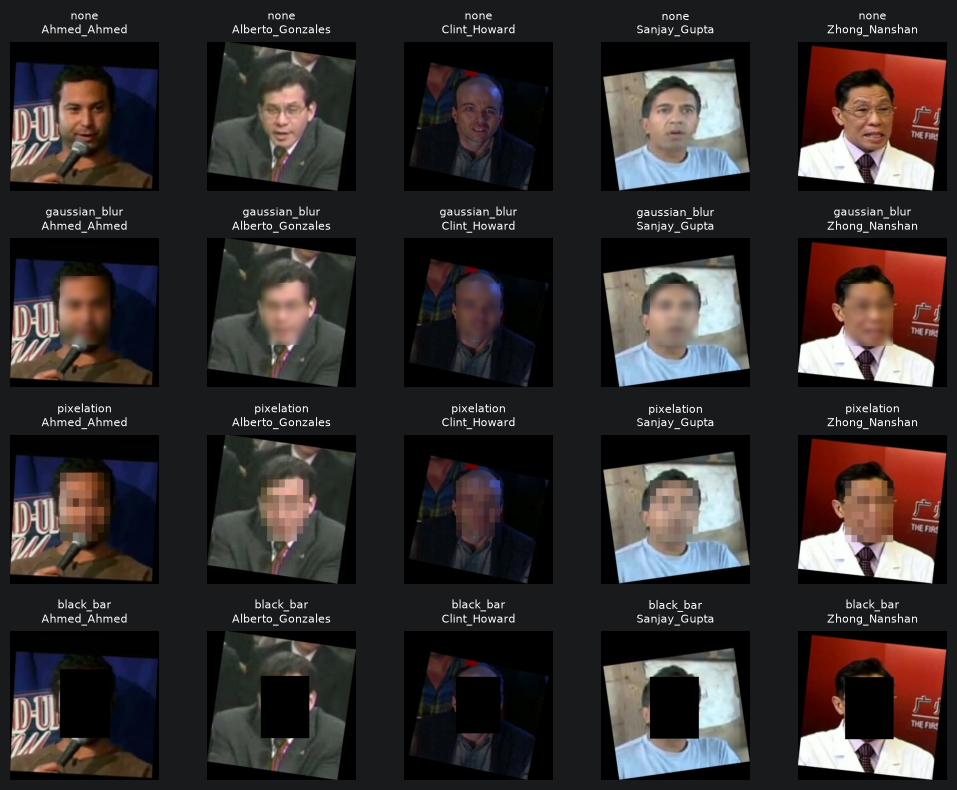

In [7]:
# Decode the results again to visually verify that every method covers the detected face
_figure, _axes = plt.subplots(
    nrows=len(results), ncols=len(samples), figsize=(2 * len(samples), 2 * len(results))
)
for _row, (method, result) in zip(_axes, results.items()):
    for _axis, (_, anonymized) in zip(_row, result.iterrows()):
        _image = cv2.imdecode(
            np.frombuffer(anonymized["image"], np.uint8), cv2.IMREAD_COLOR
        )
        _axis.imshow(cv2.cvtColor(_image, cv2.COLOR_BGR2RGB))
        _axis.set_title(
            f"{method}\n{samples.loc[anonymized['index'], 'identity']}", fontsize=8
        )
        _axis.axis("off")
plt.tight_layout()

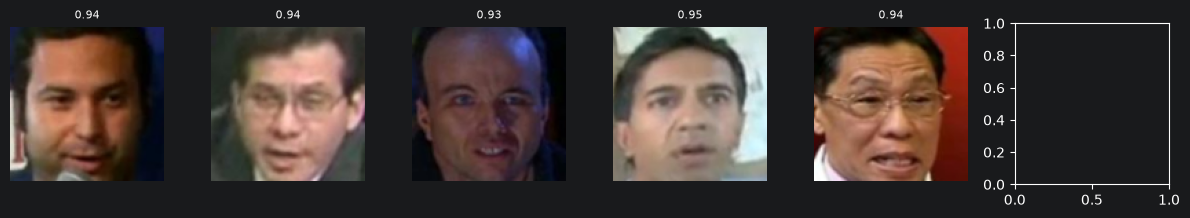

In [6]:
# Sanity-check the alignment the embedders rely on. Every embedding model is fed the crop
# produced here, so if these faces came out mirrored or rotated, recognition accuracy would
# collapse while every individual step still looked plausible.
_figure, _axes = plt.subplots(1, 6, figsize=(12, 2.2))
for _axis, (_, _sample) in zip(_axes, samples.head(6).iterrows()):
    _image = cv2.imread(str(DATASET_PATH / _sample["path"]))
    _face = detector.detect_best(_image)
    _crop = align_face(_image, _face.landmarks)
    _axis.imshow(cv2.cvtColor(_crop, cv2.COLOR_BGR2RGB))
    _axis.set_title(f"{_face.confidence:.2f}", fontsize=8)
    _axis.axis("off")
plt.tight_layout()